In [107]:
"""
Question: Can past reported incidents forecast next-month crime counts for each of 21 LAPD areas?
Target: monthly incident count by report date and LAPD area; this is not crime occurrence or individual risk.
H1: at least one candidate has lower 2022 rolling-origin MAE than the 12-month seasonal-naive rule.
H2: error increases after the March 2024 records-system transition.
Primary metric: mean absolute error (MAE); secondary metrics: WAPE, RMSE, Poisson deviance.
Validation: 12 expanding-window origins in 2022; one final 2023 evaluation; 2024 is a shift stress test.
Selection: lowest mean monthly validation MAE; four configurations per trainable model family.
Models: historical rules, Ridge, Poisson, random forest, histogram boosting, and XGBoost.
Only past counts, calendar terms, and area are features. Seed 42. Claims are predictive, not causal.
"""

'\nQuestion: Can past reported incidents forecast next-month crime counts for each of 21 LAPD areas?\nTarget: monthly incident count by report date and LAPD area; this is not crime occurrence or individual risk.\nH1: at least one candidate has lower 2022 rolling-origin MAE than the 12-month seasonal-naive rule.\nH2: error increases after the March 2024 records-system transition.\nPrimary metric: mean absolute error (MAE); secondary metrics: WAPE, RMSE, Poisson deviance.\nValidation: 12 expanding-window origins in 2022; one final 2023 evaluation; 2024 is a shift stress test.\nSelection: lowest mean monthly validation MAE; four configurations per trainable model family.\nModels: historical rules, Ridge, Poisson, random forest, histogram boosting, and XGBoost.\nOnly past counts, calendar terms, and area are features. Seed 42. Claims are predictive, not causal.\n'

In [108]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import PoissonRegressor, Ridge
from sklearn.metrics import mean_poisson_deviance, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

In [109]:
DATA_FILE = Path("../data/raw/CrimeData.csv")
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

SEED = 42
CV_MONTHS = pd.date_range("2022-01-01", "2022-12-01", freq="MS")
TEST_YEAR = 2023
STRESS_YEAR = 2024

In [110]:
BLUE, ORANGE, GREY = "#2563eb", "#ea580c", "#64748b"
plt.rcParams.update({
    "figure.figsize": (8, 4), "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "axes.titlelocation": "left", "axes.titleweight": "bold",
})

In [111]:
USE_COLUMNS = ["DR_NO", "Date Rptd", "DATE OCC", "AREA", "AREA NAME"]
raw = pd.read_csv(DATA_FILE, usecols=USE_COLUMNS)
print("Rows and columns loaded:", raw.shape)
raw.head()

Rows and columns loaded: (1004894, 5)


,DR_NO,Date Rptd,DATE OCC,AREA,AREA NAME
0,211507896,2021 Apr 11 12:00:00 AM,2020 Nov 07 12:00:00 AM,15,N Hollywood
1,201516622,2020 Oct 21 12:00:00 AM,2020 Oct 18 12:00:00 AM,15,N Hollywood
2,240913563,2024 Dec 10 12:00:00 AM,2020 Oct 30 12:00:00 AM,9,Van Nuys
3,210704711,2020 Dec 24 12:00:00 AM,2020 Dec 24 12:00:00 AM,7,Wilshire
4,201418201,2020 Oct 03 12:00:00 AM,2020 Sep 29 12:00:00 AM,14,Pacific


In [112]:
print(raw.dtypes)
print("Missing cells:", int(raw.isna().sum().sum()))
print("Duplicate incident IDs:", int(raw["DR_NO"].duplicated().sum()))
print("LAPD areas:", raw["AREA"].nunique())

DR_NO        int64
Date Rptd      str
DATE OCC       str
AREA         int64
AREA NAME      str
dtype: object
Missing cells: 0
Duplicate incident IDs: 0
LAPD areas: 21


In [113]:
DATE_FORMAT = "%Y %b %d %I:%M:%S %p"
raw["report_date"] = pd.to_datetime(raw["Date Rptd"], format=DATE_FORMAT)
raw["occur_date"] = pd.to_datetime(raw["DATE OCC"], format=DATE_FORMAT)
print("Report dates:", raw.report_date.min(), "to", raw.report_date.max())
print("Occurrence dates:", raw.occur_date.min(), "to", raw.occur_date.max())

Report dates: 2020-01-01 00:00:00 to 2025-03-28 00:00:00
Occurrence dates: 2020-01-01 00:00:00 to 2024-12-30 00:00:00


In [114]:
late_reports = raw.loc[raw.report_date.dt.year > 2024, "report_date"].dt.year.value_counts().sort_index()
print("Reports dated after the study window:")
print(late_reports)

Reports dated after the study window:
report_date
2025    94
Name: count, dtype: int64


In [115]:
area_map = raw[["AREA", "AREA NAME"]].drop_duplicates().sort_values("AREA")
print("One name per area:", area_map.groupby("AREA")["AREA NAME"].nunique().eq(1).all())
area_map.to_csv(RESULTS / "table_01_area_map.csv", index=False)
area_map

One name per area: True


,AREA,AREA NAME
107,1,Central
55,2,Rampart
6,3,Southwest
5,4,Hollenbeck
693,5,Harbor
10,6,Hollywood
3,7,Wilshire
177,8,West LA
2,9,Van Nuys
582,10,West Valley


In [116]:
study = raw.loc[raw.report_date < "2025-01-01", ["DR_NO", "report_date", "AREA"]].copy()
study["month"] = study.report_date.dt.to_period("M").dt.to_timestamp()
print("Records through 2024:", f"{len(study):,}")
print(study.report_date.dt.year.value_counts().sort_index())

Records through 2024: 1,004,800
report_date
2020    192708
2021    208285
2022    235067
2023    234636
2024    134104
Name: count, dtype: int64


In [117]:
months = pd.date_range("2020-01-01", "2024-12-01", freq="MS")
panel = pd.MultiIndex.from_product([area_map.AREA, months], names=["AREA", "month"]).to_frame(index=False)
counts = study.groupby(["AREA", "month"]).size().rename("crime_count").reset_index()
panel = panel.merge(counts, how="left").merge(area_map, on="AREA")
panel["crime_count"] = panel.crime_count.fillna(0).astype(int)
panel = panel.sort_values(["AREA", "month"]).reset_index(drop=True)
print("Area-month rows:", panel.shape)

Area-month rows: (1260, 4)


In [118]:
complete = panel.groupby("month").size().eq(area_map.AREA.nunique())
print("Every month has all 21 areas:", complete.all())
print("Zero-count area-months:", int(panel.crime_count.eq(0).sum()))
panel.head()

Every month has all 21 areas: True
Zero-count area-months: 0


,AREA,month,crime_count,AREA NAME
0,1,2020-01-01,1101,Central
1,1,2020-02-01,1065,Central
2,1,2020-03-01,931,Central
3,1,2020-04-01,796,Central
4,1,2020-05-01,892,Central


In [119]:
yearly = panel.assign(year=panel.month.dt.year).groupby("year").crime_count.sum().rename("reports")
yearly.to_csv(RESULTS / "table_02_yearly_reports.csv")
yearly

year
2020    192708
2021    208285
2022    235067
2023    234636
2024    134104
Name: reports, dtype: int64

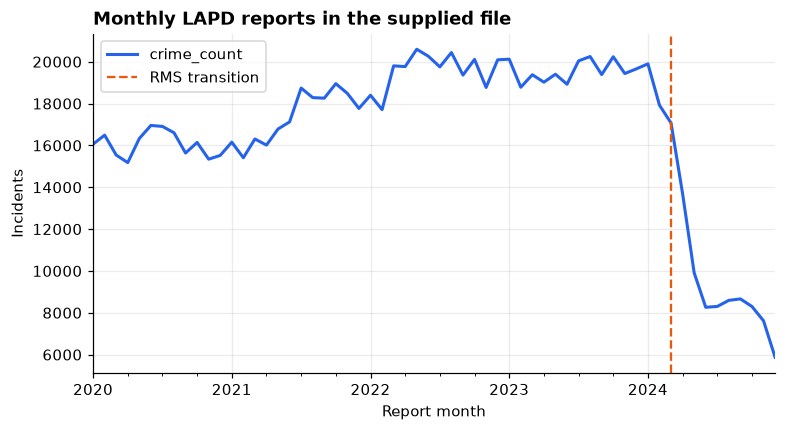

In [120]:
city_month = panel.groupby("month").crime_count.sum()
ax = city_month.plot(color=BLUE, linewidth=2)
ax.axvline(pd.Timestamp("2024-03-07"), color=ORANGE, linestyle="--", label="RMS transition")
ax.set(title="Monthly LAPD reports in the supplied file", xlabel="Report month", ylabel="Incidents")
ax.legend()
plt.savefig(RESULTS / "fig_01_monthly_reports.png", bbox_inches="tight")
plt.show()

In [121]:
grouped_count = panel.groupby("AREA").crime_count
for lag in [1, 2, 3, 6, 12]:
    panel[f"lag_{lag}"] = grouped_count.shift(lag)
panel[["AREA", "month", "crime_count", "lag_1", "lag_12"]].head(15)

,AREA,month,crime_count,lag_1,lag_12
0,1,2020-01-01,1101,NaN,NaN
1,1,2020-02-01,1065,1101.0,NaN
2,1,2020-03-01,931,1065.0,NaN
3,1,2020-04-01,796,931.0,NaN
4,1,2020-05-01,892,796.0,NaN
5,1,2020-06-01,965,892.0,NaN
6,1,2020-07-01,929,965.0,NaN
7,1,2020-08-01,1027,929.0,NaN
8,1,2020-09-01,932,1027.0,NaN
9,1,2020-10-01,914,932.0,NaN


In [122]:
for window in [3, 6, 12]:
    panel[f"roll_mean_{window}"] = grouped_count.transform(
        lambda values: values.shift(1).rolling(window).mean()
    )
panel["roll_std_6"] = grouped_count.transform(lambda values: values.shift(1).rolling(6).std())

In [123]:
panel["trend"] = (panel.month.dt.year - 2020) * 12 + panel.month.dt.month - 1
panel["month_sin"] = np.sin(2 * np.pi * panel.month.dt.month / 12)
panel["month_cos"] = np.cos(2 * np.pi * panel.month.dt.month / 12)
panel[["month", "trend", "month_sin", "month_cos"]].drop_duplicates().head(12)

,month,trend,month_sin,month_cos
0,2020-01-01,0,5.000000e-01,8.660254e-01
1,2020-02-01,1,8.660254e-01,5.000000e-01
2,2020-03-01,2,1.000000e+00,6.123234e-17
3,2020-04-01,3,8.660254e-01,-5.000000e-01
4,2020-05-01,4,5.000000e-01,-8.660254e-01
5,2020-06-01,5,1.224647e-16,-1.000000e+00
6,2020-07-01,6,-5.000000e-01,-8.660254e-01
7,2020-08-01,7,-8.660254e-01,-5.000000e-01
8,2020-09-01,8,-1.000000e+00,-1.836970e-16
9,2020-10-01,9,-8.660254e-01,5.000000e-01


In [124]:
FEATURES = [
    "AREA", "trend", "month_sin", "month_cos", "lag_1", "lag_2", "lag_3", "lag_6",
    "lag_12", "roll_mean_3", "roll_mean_6", "roll_mean_12", "roll_std_6",
]
data = panel.dropna(subset=FEATURES).reset_index(drop=True)
print("Usable rows:", data.shape)
print("Usable months:", data.month.min(), "to", data.month.max())

Usable rows: (1008, 16)
Usable months: 2021-01-01 00:00:00 to 2024-12-01 00:00:00


In [125]:
lag_check = data.merge(panel[["AREA", "month", "crime_count"]], on=["AREA", "month"], suffixes=("", "_copy"))
previous = panel.assign(month=panel.month + pd.offsets.MonthBegin(1))[["AREA", "month", "crime_count"]]
lag_check = lag_check.merge(previous, on=["AREA", "month"], suffixes=("", "_previous"))
print("lag_1 equals the previous month's count:", lag_check.lag_1.eq(lag_check.crime_count_previous).all())

lag_1 equals the previous month's count: True


In [126]:
print("CV origins:", CV_MONTHS.min(), "to", CV_MONTHS.max(), f"({len(CV_MONTHS)} months)")
print("Final evaluation rows:", data.month.dt.year.eq(TEST_YEAR).sum())
print("Stress-test rows:", data.month.dt.year.eq(STRESS_YEAR).sum())
print("No 2023 row in model-selection data:", data.loc[data.month.isin(CV_MONTHS)].month.dt.year.eq(2023).sum() == 0)

CV origins: 2022-01-01 00:00:00 to 2022-12-01 00:00:00 (12 months)
Final evaluation rows: 252
Stress-test rows: 252
No 2023 row in model-selection data: True


In [127]:
preprocess = ColumnTransformer([
    ("area", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["AREA"]),
    ("numeric", StandardScaler(), FEATURES[1:]),
])

def pipeline(model):
    return Pipeline([("preprocess", preprocess), ("model", model)])

In [128]:
model_specs = {}
for alpha in [0.1, 1.0, 10.0, 100.0]:
    model_specs[("Ridge", f"alpha={alpha:g}")] = pipeline(Ridge(alpha=alpha))
for alpha in [0.0, 0.01, 0.1, 1.0]:
    model_specs[("Poisson", f"alpha={alpha:g}")] = pipeline(PoissonRegressor(alpha=alpha, max_iter=2000))

In [129]:
for depth in [None, 12]:
    for leaf in [1, 3]:
        label = f"depth={depth}, leaf={leaf}"
        model = RandomForestRegressor(
            n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
            max_features=0.8, n_jobs=-1, random_state=SEED,
        )
        model_specs[("Random forest", label)] = pipeline(model)

In [130]:
for leaves in [15, 31]:
    for penalty in [0.0, 1.0]:
        label = f"leaves={leaves}, L2={penalty:g}"
        model = HistGradientBoostingRegressor(
            loss="poisson", max_iter=300, learning_rate=0.05, max_leaf_nodes=leaves,
            l2_regularization=penalty, random_state=SEED,
        )
        model_specs[("Histogram boosting", label)] = pipeline(model)

In [131]:
for depth in [2, 3]:
    for rate in [0.03, 0.07]:
        label = f"depth={depth}, rate={rate}"
        model = XGBRegressor(
            objective="count:poisson", n_estimators=500, max_depth=depth, learning_rate=rate,
            subsample=0.9, colsample_bytree=0.9, n_jobs=-1, random_state=SEED,
        )
        model_specs[("XGBoost", label)] = pipeline(model)

In [132]:
budget = pd.Series([family for family, config in model_specs]).value_counts().sort_index()
print("Configurations per trainable family:")
print(budget)

Configurations per trainable family:
Histogram boosting    4
Poisson               4
Random forest         4
Ridge                 4
XGBoost               4
Name: count, dtype: int64


In [133]:
RULE_COLUMNS = {
    "previous month": "lag_1", "3-month mean": "roll_mean_3",
    "6-month mean": "roll_mean_6", "seasonal naive": "lag_12",
}
rule_data = data.loc[data.month.isin(CV_MONTHS), ["AREA", "month", "crime_count"]].copy()
rule_frames = []
for name, column in RULE_COLUMNS.items():
    frame = rule_data.assign(family="Historical rule", config=name, predicted=data.loc[rule_data.index, column].values)
    rule_frames.append(frame)
rule_points = pd.concat(rule_frames, ignore_index=True)

In [134]:
def rolling_predictions(family, config, estimator):
    frames = []
    for month in CV_MONTHS:
        train_rows = data.month.lt(month)
        valid_rows = data.month.eq(month)
        fitted = clone(estimator).fit(data.loc[train_rows, FEATURES], data.loc[train_rows, "crime_count"])
        predicted = np.clip(fitted.predict(data.loc[valid_rows, FEATURES]), 0, None)
        frame = data.loc[valid_rows, ["AREA", "month", "crime_count"]].copy()
        frame = frame.assign(family=family, config=config, predicted=predicted)
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)

In [ ]:
model_frames = []
for (family, config), estimator in model_specs.items():
    model_frames.append(rolling_predictions(family, config, estimator))
model_points = pd.concat(model_frames, ignore_index=True)
cv_points = pd.concat([rule_points, model_points], ignore_index=True)
print("Stored out-of-time validation predictions:", f"{len(cv_points):,}")

In [ ]:
cv_points["absolute_error"] = (cv_points.crime_count - cv_points.predicted).abs()
cv_monthly = cv_points.groupby(["family", "config", "month"]).agg(
    mae=("absolute_error", "mean"), error_total=("absolute_error", "sum"),
    actual_total=("crime_count", "sum"),
).reset_index()
cv_monthly["wape"] = cv_monthly.error_total / cv_monthly.actual_total

In [ ]:
cv_summary = cv_monthly.groupby(["family", "config"]).agg(
    mae_mean=("mae", "mean"), mae_sd=("mae", "std"), wape_mean=("wape", "mean"),
).reset_index().sort_values("mae_mean")
best_configs = cv_summary.groupby("family", as_index=False).first().sort_values("mae_mean")
cv_summary.to_csv(RESULTS / "table_03_all_validation_configs.csv", index=False)
best_configs.to_csv(RESULTS / "table_04_best_validation_models.csv", index=False)
best_configs.round(3)

,family,config,mae_mean,mae_sd,wape_mean
1,Historical rule,3-month mean,57.931,15.825,0.062
4,Ridge,alpha=100,60.107,13.441,0.064
5,XGBoost,"depth=2, rate=0.03",61.114,16.035,0.066
3,Random forest,"depth=12, leaf=1",61.240,15.293,0.066
2,Poisson,alpha=0.1,62.868,15.857,0.068
0,Histogram boosting,"leaves=31, L2=1",66.944,15.670,0.072


In [ ]:
comparison_table = best_configs.rename(columns={
    "family": "Model family", "config": "Best configuration",
    "mae_mean": "Validation MAE", "mae_sd": "MAE SD", "wape_mean": "WAPE",
}).reset_index(drop=True)
comparison_table.insert(0, "Rank", np.arange(1, len(comparison_table) + 1))
comparison_table["WAPE (%)"] = comparison_table.pop("WAPE") * 100
comparison_table.to_csv(RESULTS / "table_04_model_comparison.csv", index=False)
print(comparison_table.round(2).to_string(index=False))

 Rank       Model family Best configuration  Validation MAE  MAE SD  WAPE (%)
    1    Historical rule       3-month mean           57.93   15.83      6.21
    2              Ridge          alpha=100           60.11   13.44      6.45
    3            XGBoost depth=2, rate=0.03           61.11   16.03      6.55
    4      Random forest   depth=12, leaf=1           61.24   15.29      6.58
    5            Poisson          alpha=0.1           62.87   15.86      6.76
    6 Histogram boosting    leaves=31, L2=1           66.94   15.67      7.17


In [ ]:
champion = best_configs.iloc[0]
CHAMPION_FAMILY = champion.family
CHAMPION_CONFIG = champion.config
print("Selected by rolling validation:", CHAMPION_FAMILY, "-", CHAMPION_CONFIG)
print("Mean monthly MAE:", round(champion.mae_mean, 2))

Selected by rolling validation: Historical rule - 3-month mean
Mean monthly MAE: 57.93


In [ ]:
seasonal_mae = cv_summary.loc[
    (cv_summary.family == "Historical rule") & (cv_summary.config == "seasonal naive"), "mae_mean"
].iloc[0]
print("Seasonal-naive validation MAE:", round(seasonal_mae, 2))
print("H1 supported by validation:", champion.mae_mean < seasonal_mae)

Seasonal-naive validation MAE: 121.3
H1 supported by validation: True


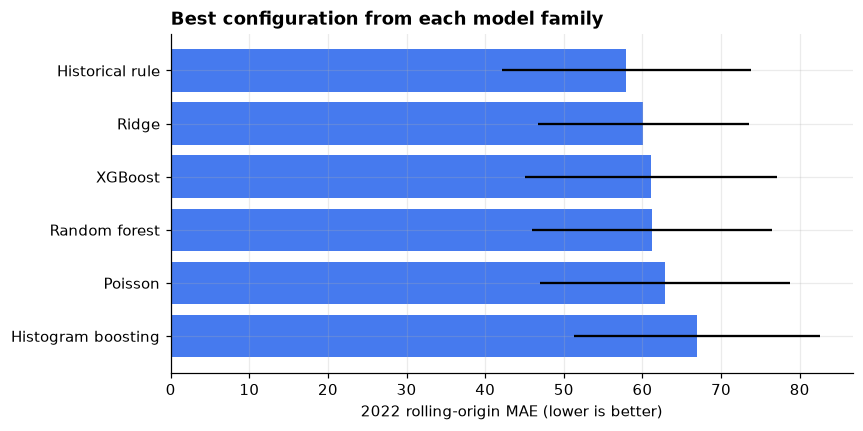

In [ ]:
plot_cv = best_configs.sort_values("mae_mean", ascending=False)
plt.barh(plot_cv.family, plot_cv.mae_mean, xerr=plot_cv.mae_sd, color=BLUE, alpha=0.85)
plt.xlabel("2022 rolling-origin MAE (lower is better)")
plt.title("Best configuration from each model family")
plt.savefig(RESULTS / "fig_02_validation_mae.png", bbox_inches="tight")
plt.show()

In [ ]:
selected_cv = cv_points.loc[
    (cv_points.family == CHAMPION_FAMILY) & (cv_points.config == CHAMPION_CONFIG)
].copy()
interval_radius = selected_cv.absolute_error.quantile(0.90, interpolation="higher")
print("Approximate 90% interval radius from 2022 rolling errors:", round(interval_radius, 1))

Approximate 90% interval radius from 2022 rolling errors: 119.3


In [ ]:
def selected_prediction(train_end, evaluation_year):
    evaluation = data.month.dt.year.eq(evaluation_year)
    if CHAMPION_FAMILY == "Historical rule":
        return data.loc[evaluation, RULE_COLUMNS[CHAMPION_CONFIG]].to_numpy(), None
    estimator = model_specs[(CHAMPION_FAMILY, CHAMPION_CONFIG)]
    training = data.month.lt(train_end)
    fitted = clone(estimator).fit(data.loc[training, FEATURES], data.loc[training, "crime_count"])
    return np.clip(fitted.predict(data.loc[evaluation, FEATURES]), 0, None), fitted

In [ ]:
test_rows = data.month.dt.year.eq(TEST_YEAR)
y_pred, final_model = selected_prediction("2023-01-01", TEST_YEAR)
test_results = data.loc[test_rows, ["AREA", "AREA NAME", "month", "crime_count", "lag_12"]].copy()
test_results["predicted"] = y_pred
test_results["lower_90"] = np.clip(y_pred - interval_radius, 0, None)
test_results["upper_90"] = y_pred + interval_radius
test_results.to_csv(RESULTS / "table_05_test_predictions.csv", index=False)

In [ ]:
test_results["absolute_error"] = (test_results.crime_count - test_results.predicted).abs()
covered = test_results.crime_count.between(test_results.lower_90, test_results.upper_90).mean()
test_metrics = pd.Series({
    "MAE": test_results.absolute_error.mean(),
    "WAPE": test_results.absolute_error.sum() / test_results.crime_count.sum(),
    "WAPE-based forecast score": 1 - test_results.absolute_error.sum() / test_results.crime_count.sum(),
    "RMSE": root_mean_squared_error(test_results.crime_count, test_results.predicted),
    "R2": r2_score(test_results.crime_count, test_results.predicted),
    "Poisson deviance": mean_poisson_deviance(test_results.crime_count, test_results.predicted.clip(1e-6)),
    "Approximate 90% interval coverage": covered,
}, name="value")
test_metrics.to_csv(RESULTS / "table_06_test_metrics.csv")
test_metrics.round(3)

MAE                                  48.984
WAPE                                  0.053
WAPE-based forecast score             0.947
RMSE                                 61.581
R2                                    0.891
Poisson deviance                      3.964
Approximate 90% interval coverage     0.952
Name: value, dtype: float64

In [ ]:
area_error = test_results.groupby(["AREA", "AREA NAME"]).agg(
    actual=("crime_count", "sum"), predicted=("predicted", "sum"), mae=("absolute_error", "mean")
).reset_index().sort_values("mae", ascending=False)
month_error = test_results.groupby("month").agg(
    actual=("crime_count", "sum"), predicted=("predicted", "sum"), mae=("absolute_error", "mean")
).reset_index()
area_error.to_csv(RESULTS / "table_07_test_error_by_area.csv", index=False)
month_error.to_csv(RESULTS / "table_08_test_error_by_month.csv", index=False)
area_error.head().round(1)

,AREA,AREA NAME,actual,predicted,mae
2,3,Southwest,13253,13439.3,78.6
19,20,Olympic,11855,11845.0,75.6
0,1,Central,17080,16943.7,73.2
12,13,Newton,12036,12051.0,69.9
18,19,Mission,9118,9020.0,62.2


In [ ]:
monthly_pair = test_results.assign(
    champion_error=test_results.absolute_error,
    seasonal_error=(test_results.crime_count - test_results.lag_12).abs(),
).groupby("month")[["champion_error", "seasonal_error"]].mean()
rng = np.random.default_rng(SEED)
draws = rng.integers(0, len(monthly_pair), size=(5000, len(monthly_pair)))
improvement_draws = monthly_pair.seasonal_error.to_numpy()[draws].mean(1) - monthly_pair.champion_error.to_numpy()[draws].mean(1)
improvement_ci = np.percentile(improvement_draws, [2.5, 97.5])
print("MAE improvement over seasonal naive:", round(improvement_draws.mean(), 2))
print("Month-block bootstrap 95% CI:", np.round(improvement_ci, 2))

MAE improvement over seasonal naive: 21.83
Month-block bootstrap 95% CI: [12.41 32.95]


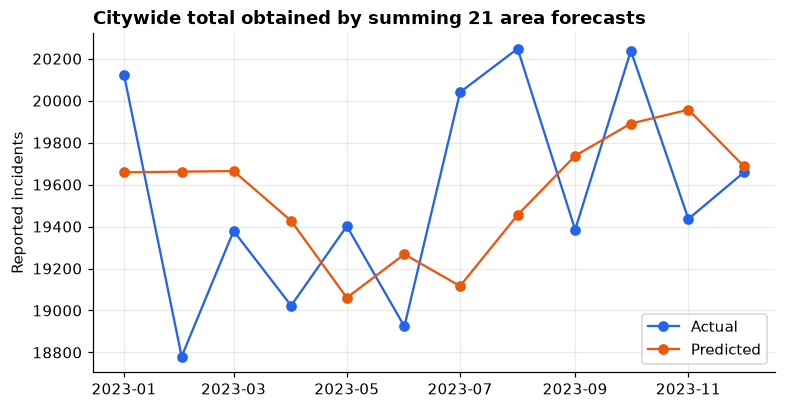

In [ ]:
plt.plot(month_error.month, month_error.actual, marker="o", label="Actual", color=BLUE)
plt.plot(month_error.month, month_error.predicted, marker="o", label="Predicted", color=ORANGE)
plt.title("Citywide total obtained by summing 21 area forecasts")
plt.ylabel("Reported incidents")
plt.legend()
plt.savefig(RESULTS / "fig_03_test_monthly_total.png", bbox_inches="tight")
plt.show()

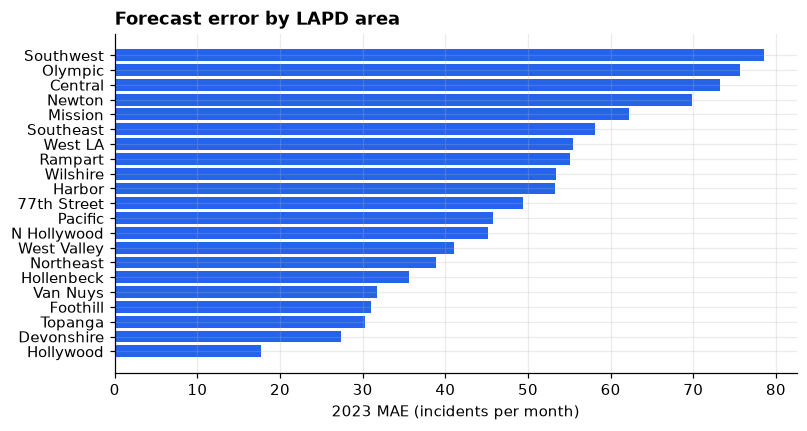

In [ ]:
area_plot = area_error.sort_values("mae")
plt.barh(area_plot["AREA NAME"], area_plot.mae, color=BLUE)
plt.xlabel("2023 MAE (incidents per month)")
plt.title("Forecast error by LAPD area")
plt.savefig(RESULTS / "fig_04_test_area_mae.png", bbox_inches="tight")
plt.show()

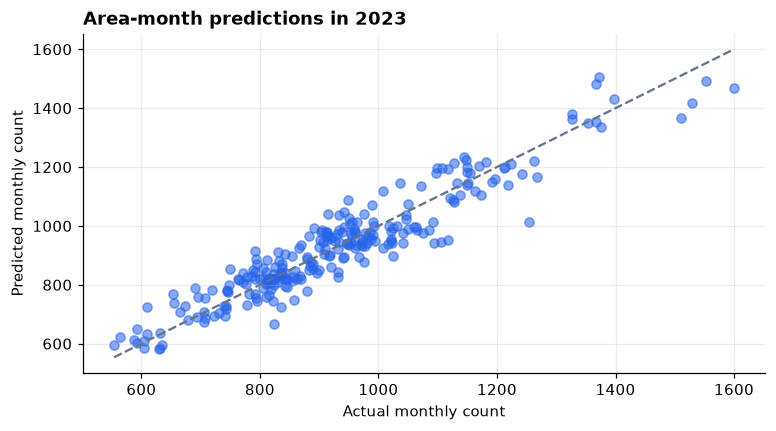

In [ ]:
low = min(test_results.crime_count.min(), test_results.predicted.min())
high = max(test_results.crime_count.max(), test_results.predicted.max())
plt.scatter(test_results.crime_count, test_results.predicted, alpha=0.55, color=BLUE)
plt.plot([low, high], [low, high], color=GREY, linestyle="--")
plt.xlabel("Actual monthly count")
plt.ylabel("Predicted monthly count")
plt.title("Area-month predictions in 2023")
plt.savefig(RESULTS / "fig_05_test_scatter.png", bbox_inches="tight")
plt.show()

In [ ]:
stress_rows = data.month.dt.year.eq(STRESS_YEAR)
stress_pred, stress_model = selected_prediction("2024-01-01", STRESS_YEAR)
stress_results = data.loc[stress_rows, ["AREA", "AREA NAME", "month", "crime_count"]].copy()
stress_results["predicted"] = stress_pred
stress_results["absolute_error"] = (stress_results.crime_count - stress_results.predicted).abs()
stress_results.to_csv(RESULTS / "table_09_2024_stress_predictions.csv", index=False)

In [ ]:
stress_metrics = pd.Series({
    "MAE": stress_results.absolute_error.mean(),
    "WAPE": stress_results.absolute_error.sum() / stress_results.crime_count.sum(),
    "RMSE": root_mean_squared_error(stress_results.crime_count, stress_results.predicted),
}, name="value")
stress_metrics.to_csv(RESULTS / "table_10_2024_stress_metrics.csv")
print(stress_metrics.round(3))
print("H2 supported:", stress_metrics.MAE > test_metrics.MAE)

MAE     122.008
WAPE      0.229
RMSE    182.275
Name: value, dtype: float64
H2 supported: True


In [ ]:
stress_month = stress_results.groupby("month").agg(
    actual=("crime_count", "sum"), predicted=("predicted", "sum"), mae=("absolute_error", "mean")
).reset_index()
stress_month["actual_to_predicted"] = stress_month.actual / stress_month.predicted
stress_month.to_csv(RESULTS / "table_11_2024_monthly_shift.csv", index=False)
stress_month.round(2)

/var/folders/vh/355cqfcs3zg2b7lwzkzk50w80000gn/T/ipykernel_59246/2791556123.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  stress_month.round(2)


,month,actual,predicted,mae,actual_to_predicted
0,2024-01-01,19898,19777.67,46.52,1.01
1,2024-02-01,17920,19664.33,86.17,0.91
2,2024-03-01,17071,19159.00,103.33,0.89
3,2024-04-01,13689,18296.33,228.76,0.75
4,2024-05-01,9911,16226.67,300.75,0.61
5,2024-06-01,8263,13557.00,263.27,0.61
6,2024-07-01,8303,10621.00,145.81,0.78
7,2024-08-01,8594,8825.67,44.52,0.97
8,2024-09-01,8663,8386.67,52.59,1.03
9,2024-10-01,8300,8520.00,33.33,0.97


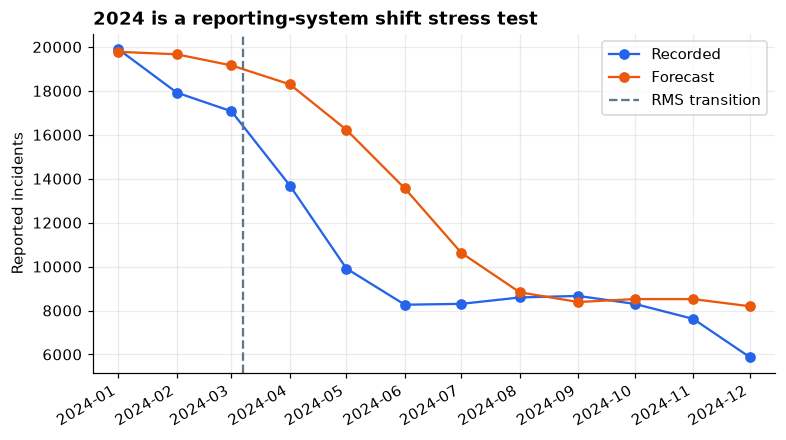

In [ ]:
plt.plot(stress_month.month, stress_month.actual, marker="o", label="Recorded", color=BLUE)
plt.plot(stress_month.month, stress_month.predicted, marker="o", label="Forecast", color=ORANGE)
plt.axvline(pd.Timestamp("2024-03-07"), color=GREY, linestyle="--", label="RMS transition")
plt.title("2024 is a reporting-system shift stress test")
plt.ylabel("Reported incidents")
plt.xticks(rotation=30, ha="right")
plt.margins(x=0.04)
plt.legend()
plt.savefig(RESULTS / "fig_06_2024_system_shift.png", bbox_inches="tight")
plt.show()

In [ ]:
headline = pd.DataFrame({
    "quantity": ["selected_family", "selected_configuration", "validation_MAE", "test_MAE", "test_WAPE", "stress_MAE"],
    "value": [CHAMPION_FAMILY, CHAMPION_CONFIG, champion.mae_mean, test_metrics.MAE, test_metrics.WAPE, stress_metrics.MAE],
})
headline.to_csv(RESULTS / "table_12_headline_results.csv", index=False)
headline

,quantity,value
0,selected_family,Historical rule
1,selected_configuration,3-month mean
2,validation_MAE,57.931217
3,test_MAE,48.984127
4,test_WAPE,0.052609
5,stress_MAE,122.007937
